# 과제 ② 요약 생성 — 텍스트·표·이미지를 검색 가능한 요약문으로


지난 시간에 PDF에서 꺼낸 **텍스트 / 표 / 이미지**를, 검색에 쓸 수 있는 **요약문(색인 카드)** 으로 바꿉니다.

```
텍스트 ──┐
  표   ──┼──▶  요약문 생성  ──▶  검색용 색인(색인 카드)
이미지 ──┘      LLM / VLM
```

# 0. API 키 불러오기

In [15]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os, time, pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        현재 폴더 이름이 "invest" 또는 "practice" 이면 상위 폴더, 아니면 현재 폴더
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ["invest", "practice", "notebooks", "src"] else Path.cwd()

# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
load_dotenv(PROJECT_ROOT / ".env")

# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
openai_api_key = os.getenv("OPENAI_API_KEY")

# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    raise ValueError("Environment variable 'OPENAI_API_KEY' is not set")

# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print(f"{openai_api_key[:7]}...{openai_api_key[-4:]}")


sk-proj...Vq0A


In [16]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인합니다.
#        openai 패키지에서 OpenAI, AuthenticationError 를 임포트하고
#        OpenAI().models.list() 를 호출해 AuthenticationError 가 나면 안내 문구와 함께 중단합니다.
from openai import OpenAI
from openai import AuthenticationError

try:
    client = OpenAI(api_key=openai_api_key)
    client.models.list()
except AuthenticationError:
    raise ValueError("The provided OpenAI API key is invalid. Please check your .env file.")    


# 1. 추출 결과 복원

In [17]:
# ⌨️ 1-1. PROJECT_ROOT / "data" / "processed_assignment" / "extracted.pkl" 경로를 pkl_path 에 담습니다.
pkl_path = PROJECT_ROOT / "data" / "processed_assignment" / "extracted.pkl"
print(f"pkl_path: {pkl_path}")
# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pkl_path, "rb") as f:
    data = pickle.load(f)
    
# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.

texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"texts 개수: {len(texts)}")
print(f"tables 개수: {len(tables)}")
print(f"texts_2k_token 개수: {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "invest" / "figures")
figures_dir = PROJECT_ROOT / "data" / "figures_assignment"
print(f"figures_dir 존재 여부: {figures_dir.exists()}")

pkl_path: /Users/huyn/Project/multimodal-rag/data/processed_assignment/extracted.pkl
texts 개수: 20
tables 개수: 12
texts_2k_token 개수: 3
figures_dir 존재 여부: True


# 2. 요약 체인 만들기

In [18]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI


def generate_text_summaries(texts, tables, summarize_texts=False):
    """
    텍스트 및 표 데이터를 요약하여 검색에 활용할 요약본을 생성합니다.

    texts          : 텍스트 리스트
    tables         : 표 리스트
    summarize_texts: 텍스트 요약을 활성화할지 여부
    """

    # Prompt 한국어 버전
    prompt_text_kor = """당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미입니다.
이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
요약할 표 또는 텍스트: {element}"""

    # Prompt 영어 버전 (한국어 결과가 부정확할 때 교체)
    # prompt_text_eng = """You are an assistant tasked with summarizing tables and text for retrieval.
    # These summaries will be embedded and used to retrieve the raw text or table elements.
    # Give a concise summary of the table or text that is well optimized for retrieval.
    # Table or text: {element}"""

    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

    # 모델: gpt-4o-mini (교재의 gpt-4 대신 저렴하고 빠른 최신 모델)
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    # 요약 체인 = 입력 포장 + 프롬프트 + LLM + 출력 파서
    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []

    # 텍스트 요약을 활성화한 경우
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    # 텍스트 요약을 사용하지 않는 경우 원본을 그대로 사용
    elif texts:
        text_summaries = texts

    # 표 데이터 요약
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})

    return text_summaries, table_summaries


print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


# 3. 텍트스/표 요약 실행

In [19]:
# ⌨️ 3-1. 시작 시각을 기록합니다.
start = time.time()

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True
text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.
print(f"요약 완료 — {time.time() - start:.1f}초 소요")
print("텍스트 요약 수:", len(text_summaries))
print("표 요약 수    :", len(table_summaries))


요약 완료 — 17.9초 소요
텍스트 요약 수: 3
표 요약 수    : 12


# 4. 요약 결과 확인

In [20]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("-" * 60)
print("texts_2k_token[0] 앞 300자:")
print(texts_2k_token[0][:300])

# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("-" * 60)
print("text_summaries[0] 전체:")
print(text_summaries[0])

# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
print("-" * 60)
original_length = len(texts_2k_token[0])
summary_length = len(text_summaries[0])
compression_rate = (summary_length / original_length) * 100
print(f"원본 글자 수: {original_length}")
print(f"요약 글자 수: {summary_length}")
print(f"압축률: {compression_rate:.2f}%")

------------------------------------------------------------
texts_2k_token[0] 앞 300자:
shareholder

letter Q3 2025

Wduolingo

our mission is to develop the best education in the world and make it universally available.

@ ZB

Q3 Highlights

User Metrics Daily Active Users Monthly Active Users Paid Subscribers at period end Paid Subscriber Penetration as % of LTM MAUs Q3 2024 37.2M 11
------------------------------------------------------------
text_summaries[0] 전체:
**Duolingo Q3 2025 Shareholder Letter Summary**

**Mission:** Duolingo aims to provide the best education globally and make it universally accessible.

**Q3 Highlights:**
- **User Metrics:**
  - Daily Active Users (DAUs): 50.5M (+36% YoY)
  - Monthly Active Users (MAUs): 135.3M (+20% YoY)
  - Paid Subscribers: 11.5M (+34% YoY), representing 9.0% of LTM MAUs.

- **Financial Metrics:**
  - Revenue: $271.7M (+41% YoY)
  - Total Bookings: $281.9M (+33% YoY)
  - Net Income: $292.2M (includes one-time tax benefit of $222.7M)
  - 

# 5. `tabel_summaries`가 비어있다면?

In [21]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.

# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
if table_summaries:
    # print(f"표 요약 => {len(table_summaries)} 건 생성됨 \n")
    # print("[표 요약 예시]")
    # print(table_summaries[0])

    # for i , summary in enumerate(table_summaries[:3]):
    #     print("="*60)
    #     print(f"[표 요약 {i+1}]")
    #     print("="*60)
    #     print(summary)
    #     print()

    #원본 표와 함께 비교하고 싶다. zip(tables, table_summaries) 두리스트에서 같은 순번끼리
    #하나씩 꺼낸다.  요약은 원본 순서대로 만들어 졌으므로 [0] [0]끼리, [1] [1] 짝을 맞춰서
    for i, (table,summary) in enumerate(zip(tables[:2], table_summaries[:2])):
            print("="*60)
            print(f"[표 {i+1} 원본 (앞 300자)]")
            print("="*60)
            print(table[:300])
            print()
            print("="*60)
            print(f"[표 {i+1} 요약 ]")
            print("="*60)
            print(summary)
            print()
else:
    print("표 요약이 비어 있습니다. " \
    "     원인은 1. strategy = 'hi_res' 2. 진짜 표인지, 그림으로 그린 표인지 확인")

[표 1 원본 (앞 300자)]
(in millions) Q3 2024 Q3 2025 YoY User Metrics Monthly active users (MAUs) 113.1 135.3 20% Daily active users (DAUs) 37.2 50.5 36% Paid subscribers (period end) 8.6 11.5 34% Operating Metrics Subscription bookings $176.3 $240.3 36% Total bookings $211.5 $281.9 33% GAAP Financial Measures Revenues $1

[표 1 요약 ]
**Q3 2024 vs Q3 2025 User and Financial Metrics Summary:**

- **User Metrics:**
  - Monthly Active Users (MAUs): 113.1M → 135.3M (20% YoY)
  - Daily Active Users (DAUs): 37.2M → 50.5M (36% YoY)
  - Paid Subscribers: 8.6M → 11.5M (34% YoY)

- **Operating Metrics:**
  - Subscription Bookings: $176.3M → $240.3M (36% YoY)
  - Total Bookings: $211.5M → $281.9M (33% YoY)

- **GAAP Financial Measures:**
  - Revenues: $192.6M → $271.7M (41% YoY)
  - Subscription Revenues: $157.6M → $229.5M (46% YoY)
  - Gross Profit: $140.4M → $196.9M (40% YoY)
  - Gross Margin: 72.9% → 72.5% (~40 bps)
  - Net Income: $23.4M → $292.2M (>100% YoY)
  - Net Cash from Operating Activities: 

# 6. 이미지를 Base64로 포장하기

In [22]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")
    
# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.
image_files = sorted(
    f for f in figures_dir.iterdir()
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")    
)
# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.
sample_b64 = encode_image(image_files[0])

print("원본파일 =>", image_files[0].name)
print("문자열 길이 =>", len(sample_b64), "자")
print("앞 100자 =>", sample_b64[:100])

원본파일 => figure-2-1.jpg
문자열 길이 => 47664 자
앞 100자 => /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


# 7. 이미지 요약 함수 만들기

In [23]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):
    """
    이미지 요약을 생성합니다.

    img_base64: base64로 인코딩된 이미지 문자열
    prompt     : 요약을 위한 프롬프트
    """
    #   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)
    #   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
    #          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    msg = chat.invoke(
        [
            HumanMessage(
            #     content=[
            #     {"type": "text", "text": prompt},
            #     {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}}
            # ]
            
                content=[
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}}
                ]
            )
        ]
    )

#   ⌨️ (3) 응답의 .content 를 반환합니다.
    return msg.content

# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = """You are an assistant that summarizes images for retrieval.
These summaries will be embedded and used to retrieve the raw images.
Please provide a concise summary of the image that is well optimized for retrieval.
Please write the summary in Korean (Hangul) at the end."""

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.
print(image_summarize(sample_b64, test_prompt))

A cute green cartoon bird with a wink and a heart symbol, conveying a playful and affectionate vibe.

귀여운 초록색 만화 새가 윙크하며 하트 심볼을 가지고 있어 장난스럽고 애정 어린 분위기를 전달합니다.


# 8. 폴더 내 전체 이미지 요약

In [24]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.
def generate_img_summaries(path):
    """
    이미지의 요약과 Base64 인코딩 문자열을 생성

    path: Unstructured에 의해 추출된 이미지 파일들의 경로
    """
    #   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.
    img_base64_list = []
    image_summaries = []    

#   ⌨️ (2) 7번과 같은 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
    These summaries will be embedded and used to retrieve the raw image.
    Provide a concise summary of the image that is well optimized for retrieval.
    The summary should be written in Korean (Hangul)."""

    # 영어 요약이 필요하면 이쪽을 사용
    # prompt_eng = """You are an assistant tasked with summarizing images for retrieval.
    # These summaries will be embedded and used to retrieve the raw image.
    # Provide a concise summary of the image that is well optimized for retrieval."""

#   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
#          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
#          → 전체 경로 만들기 → encode_image → 리스트에 추가
#          → image_summarize 결과를 요약 리스트에 추가
    for img_file in sorted(os.listdir(path)):
        # .jpg, .png, .jpeg 확장자만 처리합니다
        if img_file.endswith((".jpg", ".jpeg", ".png")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))

    return img_base64_list, image_summaries

#   ⌨️ (4) img_base64_list, image_summaries 를 반환합니다.
start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))
# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.
print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print(f"요약된 이미지 수: {len(image_summaries)}")

이미지 요약 완료 — 12.8초 소요
요약된 이미지 수: 7


# 9. 요약 품질 검증

[0] figure-2-1.jpg


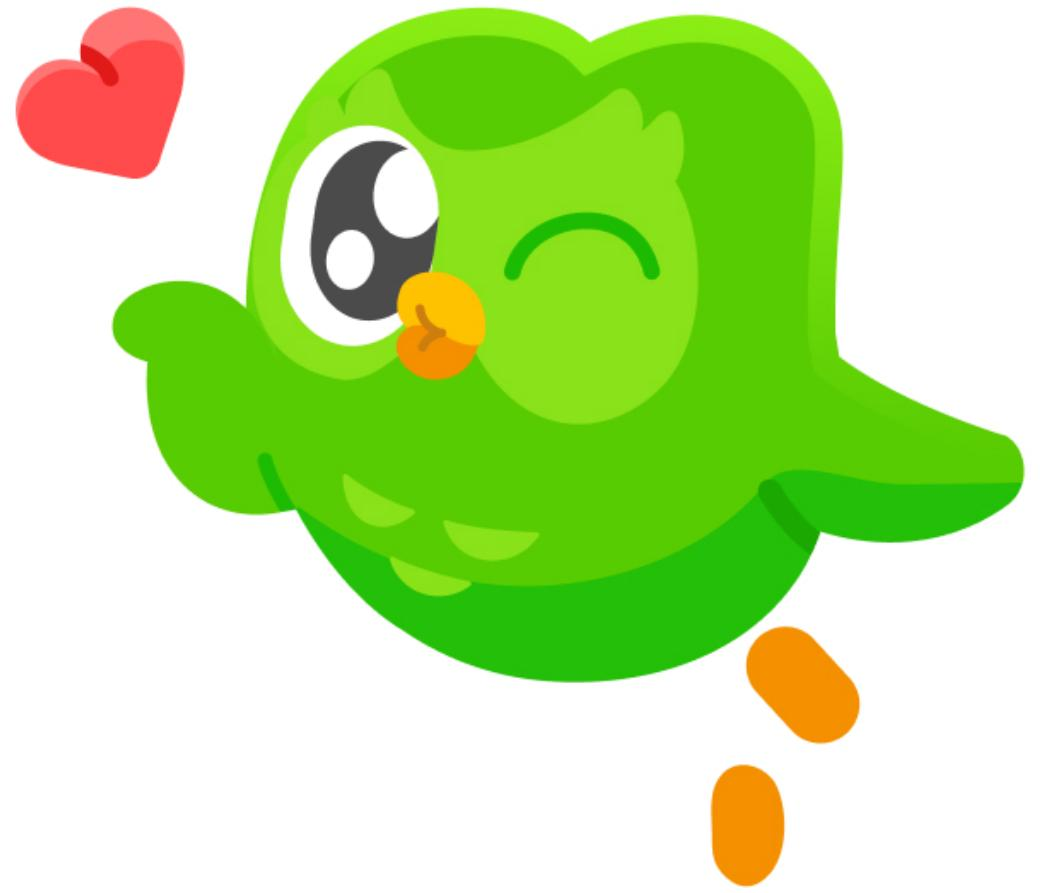

요약: 귀여운 초록색 새가 사랑을 표현하는 하트와 함께 웃고 있는 모습.

[1] figure-23-7.jpg


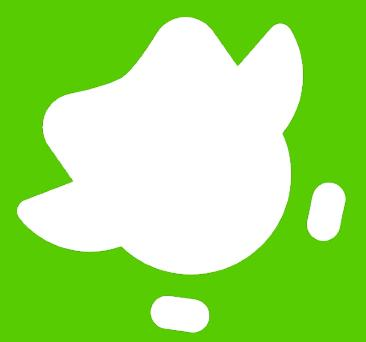

요약: 초록색 배경에 흰색의 추상적인 형태와 작은 흰색 물체들이 있는 이미지.



In [25]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
from IPython.display import Image, display

# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.

for i , (img_file, summary) in enumerate(zip(image_files[:2], image_summaries[:2])):
    print("="*60)
    print(f"[{i}] {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()

# 10. 토큰 사용량 측정

In [26]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.
import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens
input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.
print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

텍스트 요약 토큰 사용량 (추정)
  입력 : 4,956 토큰
  출력 : 1,176 토큰
  합계 : 6,132 토큰

요약한 이미지 수: 7 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


# 11. 저장

In [27]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed_assignment" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)
output_dir = PROJECT_ROOT / "data" / "processed_assignment"
output_dir.mkdir(parents=True, exist_ok=True)
# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump({
        "text_summaries": text_summaries,
        "table_summaries": table_summaries,
        "image_summaries": image_summaries,
        "img_base64_list": img_base64_list
    }, f)

# ⌨️ 11-3. 저장 경로를 출력합니다.

print("요약 데이터가 저장되었습니다:", output_dir / "summaries.pkl")


요약 데이터가 저장되었습니다: /Users/huyn/Project/multimodal-rag/data/processed_assignment/summaries.pkl
